# Module 07: Practical Training Methodology

This module teaches the professional workflow used to train deep-learning models correctly. A model is not just layers and an optimizer. It also needs the right problem definition, dataset split, preprocessing, baseline, training loop, validation loop, metrics, checkpoints, reproducibility, and error analysis.


## Module outline

* **Step 1: Problem Definition**
  * task type, input, target, prediction time, success metric, failure cost.
* **Step 2: Dataset Contract and Data Understanding**
  * row meaning, feature meaning, label meaning, dtypes, valid ranges, missing values, data card.
* **Step 3: Train / Validation / Test Splits**
  * random split, stratified split, group split, temporal split, leakage.
* **Step 4: Preprocessing Pipeline**
  * fit on train only, transform validation/test, scaling, encoding, tokenization, resizing, augmentation.
* **Step 5: Batches, Epochs, and Iterations**
  * batch size, iteration, epoch, steps per epoch, gradient accumulation.
* **Step 6: Training Loop**
  * train mode, forward pass, loss, backward pass, optimizer step, zero gradients.
* **Step 7: Validation Loop**
  * eval mode, no gradients, validation loss, validation metrics, no weight updates.
* **Step 8: Metrics and Thresholds**
  * classification, regression, multilabel, imbalanced data, threshold tuning.
* **Step 9: Baselines and Sanity Checks**
  * majority baseline, linear baseline, overfit-small-batch test, random-label test.
* **Step 10: Learning Curves and Diagnosis**
  * underfitting, overfitting, high learning rate, low learning rate, data leakage.
* **Step 11: Early Stopping and Checkpoints**
  * patience, best model, resume training, optimizer state, scheduler state.
* **Step 12: Reproducibility and Experiment Tracking**
  * seeds, configs, data version, code version, logs, artifacts.
* **Step 13: Hyperparameter Search and Ablation**
  * random search, grid search, Bayesian search, ASHA/Hyperband, one-change-at-a-time ablations.
* **Step 14: Error Analysis and Slice Evaluation**
  * false positives, false negatives, subgroup metrics, label audit, data-centric fixes.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10
rng = np.random.default_rng(42)


## Step 1: Problem Definition

**Definition:** Problem definition is the exact statement of what the model receives, what it must predict, when prediction happens, and how success is measured.

Before model code, answer:

| Question | Example |
|---|---|
| What is one input? | One customer record, one image, one sequence, one audio clip. |
| What is the target? | Class label, number, multiple tags, next value, generated text. |
| When is prediction made? | Before future events are known. |
| What metric matters? | Recall, precision, MAE, PR-AUC, latency, cost. |
| What mistake is costly? | False negative, false positive, high error, slow response. |

**Why it matters:** model architecture, loss, split method, and metric all depend on this definition.


### Task Type Map

| Task | Target format | Output layer | Common loss | Common metric |
|---|---|---|---|---|
| Binary classification | 0/1 | one sigmoid logit/probability | BCE | F1, PR-AUC, ROC-AUC |
| Multiclass classification | one class id | softmax logits | CE | accuracy, macro F1 |
| Multilabel classification | many 0/1 labels | sigmoid per label | BCE | micro/macro F1 |
| Regression | number | linear output | MAE/MSE/Huber | MAE/RMSE |
| Forecasting | future value(s) | linear sequence/head | MAE/MSE/quantile | MAE/RMSE/MAPE |

**Common mistake:** choosing model output before defining target format.


## Step 2: Dataset Contract and Data Understanding

**Definition:** A data contract describes the expected schema and meaning of the data. It prevents silent mistakes when data changes.

It should include:

* feature names;
* dtypes;
* valid ranges;
* missing-value rules;
* target definition;
* unit of observation;
* time meaning;
* allowed preprocessing.

**Simple example:** if `age` must be between 0 and 120, then `age=-1` should be caught before training.


In [2]:
schema = pd.DataFrame({
    'field':['age','income','clicked_last_7_days','signup_date','target_churned'],
    'dtype':['float','float','0/1 integer','date','0/1 integer'],
    'valid_rule':['0 to 120','>= 0','0 or 1','not future date','label known after 30 days'],
    'model_role':['feature','feature','feature','split/leakage check','target']
})
display(schema)


,field,dtype,valid_rule,model_role
0,age,float,0 to 120,feature
1,income,float,>= 0,feature
2,clicked_last_7_days,0/1 integer,0 or 1,feature
3,signup_date,date,not future date,split/leakage check
4,target_churned,0/1 integer,label known after 30 days,target


## Step 3: Train / Validation / Test Splits

**Definition:** A split separates data by purpose.

* **Train:** used to fit model parameters.
* **Validation:** used to choose hyperparameters, model versions, thresholds, and stopping point.
* **Test:** used once for final unbiased evaluation.

Split type must match the data:

| Data situation | Correct split |
|---|---|
| balanced iid rows | random split |
| imbalanced classes | stratified split |
| same user/patient appears many times | group split |
| future prediction | temporal split |

**Common mistake:** random splitting time-dependent data, which leaks future patterns.


In [3]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

X, y = make_classification(n_samples=3000, n_features=12, n_informative=5, weights=[0.9,0.1], random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
majority = np.zeros_like(y_test)
print('test class counts:', np.bincount(y_test))
print('majority accuracy:', round(accuracy_score(y_test, majority), 3))
print('majority balanced accuracy:', round(balanced_accuracy_score(y_test, majority), 3))
print('confusion matrix:\n', confusion_matrix(y_test, majority))


test class counts: [670  80]
majority accuracy: 0.893
majority balanced accuracy: 0.5
confusion matrix:
 [[670   0]
 [ 80   0]]


**Output meaning:** the majority baseline looks strong by accuracy because 90% of examples are class 0. Balanced accuracy reveals that it completely fails class 1. This is why split and metric must be chosen together.


### Leakage Types

| Leakage type | What happens | Example |
|---|---|---|
| target leakage | feature contains target information | `refund_issued` used to predict fraud before refund decision exists |
| preprocessing leakage | transformation fit on all data | scaler fit before train/test split |
| duplicate leakage | same entity appears in train and test | same patient scans in both sets |
| time leakage | future data used to predict past | random split in forecasting |
| label leakage through graph/group | connected examples reveal labels | user network split randomly |

**Rule:** ask whether this information would exist at prediction time. If not, it is leakage.


## Step 4: Preprocessing Pipeline

**Definition:** A preprocessing pipeline transforms raw data into tensors the model can use. It must be fitted only on training data.

Examples:

* numeric scaling;
* categorical encoding;
* tokenization;
* image resizing;
* missing-value imputation;
* augmentation.

**Correct rule:** `fit` on train, `transform` validation/test/live data.


In [4]:
from sklearn.preprocessing import StandardScaler

X_small = np.array([[1.0], [2.0], [3.0], [100.0]])
train = X_small[:3]
test = X_small[3:]

scaler_train_only = StandardScaler().fit(train)
scaler_leaky = StandardScaler().fit(X_small)

display(pd.DataFrame({
    'method':['fit train only','fit all data (leaky)'],
    'train_mean_used':[scaler_train_only.mean_[0], scaler_leaky.mean_[0]],
    'test_scaled_value':[scaler_train_only.transform(test)[0,0], scaler_leaky.transform(test)[0,0]]
}))


,method,train_mean_used,test_scaled_value
0,fit train only,2.0,120.024997
1,fit all data (leaky),26.5,1.731810


**Output meaning:** fitting the scaler on all data lets the extreme test value influence the mean and standard deviation. That is preprocessing leakage.


## Step 5: Batches, Epochs, and Iterations

**Definitions:**

* **Batch size:** number of examples used for one gradient update.
* **Iteration / step:** one optimizer update.
* **Epoch:** one full pass over the training data.
* **Steps per epoch:** `ceil(number_of_training_examples / batch_size)`.
* **Gradient accumulation:** add gradients over several mini-batches before one optimizer step.

These definitions matter because learning-rate schedules, logging, checkpointing, and compute budget are often step-based.


In [5]:
dataset_size = 10500
batch_sizes = [16, 32, 64, 128, 256, 512]
display(pd.DataFrame({
    'batch_size': batch_sizes,
    'steps_per_epoch': [int(np.ceil(dataset_size/b)) for b in batch_sizes],
    'updates_in_10_epochs': [int(np.ceil(dataset_size/b))*10 for b in batch_sizes],
}))


,batch_size,steps_per_epoch,updates_in_10_epochs
0,16,657,6570
1,32,329,3290
2,64,165,1650
3,128,83,830
4,256,42,420
5,512,21,210


## Step 6: Training Loop

**Definition:** The training loop is the repeated process that updates parameters.

Typical order:

1. set model to train mode;
2. get batch;
3. forward pass;
4. compute loss;
5. clear old gradients;
6. backward pass;
7. optimizer step;
8. log loss/metrics.

**Common mistake:** forgetting to clear gradients. Many frameworks accumulate gradients by default.


In [6]:
training_loop = pd.DataFrame({
    'step':[1,2,3,4,5,6,7],
    'operation':['model.train()','forward pass','compute loss','zero gradients','backward pass','optimizer step','log values'],
    'why':['enable train-time behavior','make predictions','measure error','remove old gradients','compute gradients','update weights','debug training']
})
display(training_loop)


,step,operation,why
0,1,model.train(),enable train-time behavior
1,2,forward pass,make predictions
2,3,compute loss,measure error
3,4,zero gradients,remove old gradients
4,5,backward pass,compute gradients
5,6,optimizer step,update weights
6,7,log values,debug training


## Step 7: Validation Loop

**Definition:** The validation loop evaluates the model without changing weights.

Correct validation:

* model in eval mode;
* no gradient tracking;
* no optimizer step;
* no fitting preprocessing;
* compute validation metrics.

**Why it matters:** validation estimates generalization during model development. If validation updates weights or leaks information, it becomes training data.


### Train Loop vs Validation Loop

| Item | Training | Validation |
|---|---|---|
| model mode | train | eval |
| gradients | enabled | disabled |
| dropout | active | disabled |
| BatchNorm | batch statistics | running statistics |
| optimizer step | yes | no |
| purpose | learn parameters | estimate generalization |


## Step 8: Metrics and Thresholds

**Definition:** A metric summarizes prediction quality in a task-specific way. A threshold converts probabilities into class decisions.

For imbalanced binary classification, threshold choice can matter as much as model choice.


,threshold,precision,recall,F1
9,0.50,0.933333,0.84,0.884211
8,0.45,0.857143,0.90,0.878049
7,0.40,0.810345,0.94,0.870370
10,0.55,0.974684,0.77,0.860335
6,0.35,0.698529,0.95,0.805085


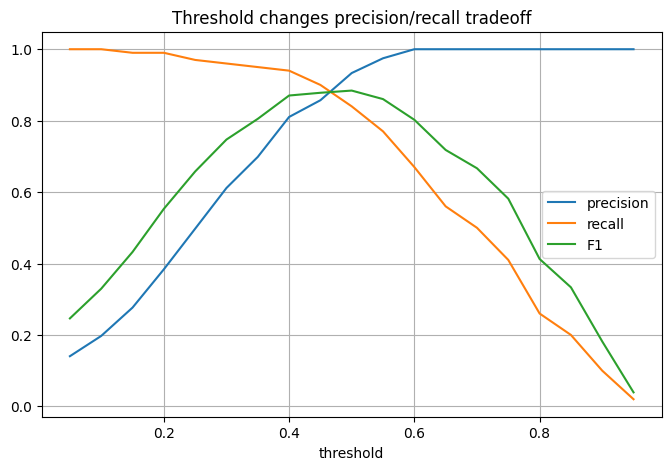

In [7]:
from sklearn.metrics import precision_recall_curve, f1_score

y_true = np.r_[np.zeros(900), np.ones(100)]
scores = np.r_[rng.beta(1, 8, 900), rng.beta(4, 2, 100)]
thresholds = np.linspace(0.05, 0.95, 19)
rows = []
for t in thresholds:
    pred = (scores >= t).astype(int)
    tp = ((pred==1)&(y_true==1)).sum()
    fp = ((pred==1)&(y_true==0)).sum()
    fn = ((pred==0)&(y_true==1)).sum()
    precision = tp/(tp+fp+1e-9)
    recall = tp/(tp+fn+1e-9)
    rows.append([t, precision, recall, f1_score(y_true, pred)])
df = pd.DataFrame(rows, columns=['threshold','precision','recall','F1'])
display(df.sort_values('F1', ascending=False).head())
plt.plot(df.threshold, df.precision, label='precision')
plt.plot(df.threshold, df.recall, label='recall')
plt.plot(df.threshold, df.F1, label='F1')
plt.title('Threshold changes precision/recall tradeoff')
plt.xlabel('threshold'); plt.legend();


**Output meaning:** lower thresholds usually improve recall but reduce precision. Higher thresholds reduce false positives but can miss positives.


## Step 9: Baselines and Sanity Checks

**Definition:** A baseline is a simple reference result. A sanity check tests whether the training system is capable of learning at all.

Important baselines/checks:

* majority class baseline;
* simple linear/logistic model;
* previous production model;
* overfit a tiny batch;
* random-label test;
* data shape and label audit.

**If a deep model cannot overfit a tiny batch, do not run full training yet.** Something is likely wrong in data, loss, optimizer, or model wiring.


## Step 10: Learning Curves and Diagnosis

Learning curves are one of the most important training tools.

| Pattern | Meaning | Possible action |
|---|---|---|
| train high, validation high | underfitting | bigger model, better features, more training |
| train low, validation high | overfitting | regularization, augmentation, more data |
| both unstable | LR too high or data/loss bug | lower LR, inspect gradients/data |
| train improves, validation flat | mismatch or overfitting | error analysis, split check |


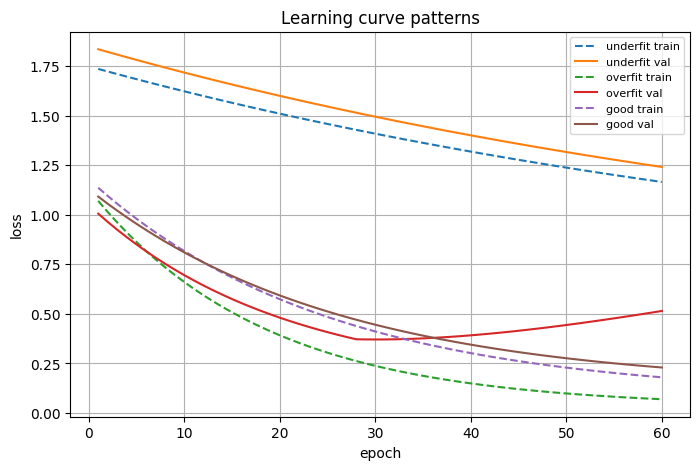

In [8]:
epochs = np.arange(1, 61)
under_train = 1.2*np.exp(-epochs/90)+0.55
under_val = 1.25*np.exp(-epochs/90)+0.60
over_train = 1.1*np.exp(-epochs/18)+0.03
over_val = 0.9*np.exp(-epochs/20)+0.15+0.01*np.maximum(epochs-28,0)
good_train = 1.1*np.exp(-epochs/25)+0.08
good_val = 1.0*np.exp(-epochs/26)+0.13
plt.plot(epochs, under_train, '--', label='underfit train')
plt.plot(epochs, under_val, label='underfit val')
plt.plot(epochs, over_train, '--', label='overfit train')
plt.plot(epochs, over_val, label='overfit val')
plt.plot(epochs, good_train, '--', label='good train')
plt.plot(epochs, good_val, label='good val')
plt.title('Learning curve patterns')
plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(fontsize=8);


## Step 11: Early Stopping and Checkpoints

**Early stopping definition:** stop training when validation performance has not improved for a chosen patience period.

**Checkpoint definition:** saved training state that can be restored later.

A good checkpoint may include:

* model weights;
* optimizer state;
* scheduler state;
* epoch/step;
* best validation metric;
* config;
* preprocessing version.


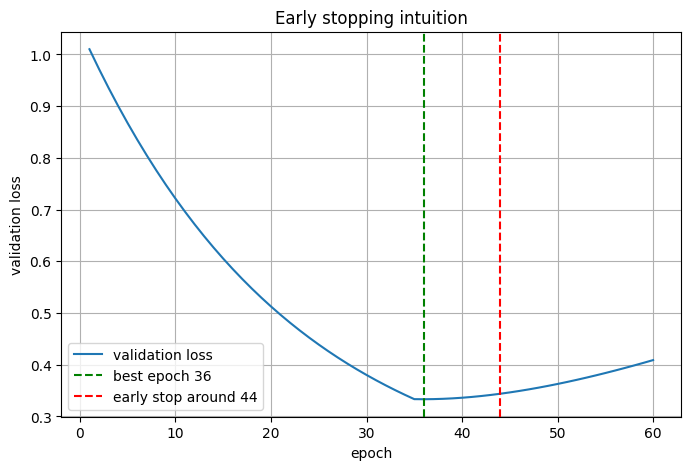

In [9]:
val_loss = 0.9*np.exp(-epochs/22)+0.15+0.008*np.maximum(epochs-35,0)
best_epoch = int(np.argmin(val_loss)+1)
patience = 8
stop_epoch = min(best_epoch + patience, len(epochs))
plt.plot(epochs, val_loss, label='validation loss')
plt.axvline(best_epoch, color='green', linestyle='--', label=f'best epoch {best_epoch}')
plt.axvline(stop_epoch, color='red', linestyle='--', label=f'early stop around {stop_epoch}')
plt.title('Early stopping intuition')
plt.xlabel('epoch'); plt.ylabel('validation loss'); plt.legend();


## Step 12: Reproducibility and Experiment Tracking

**Definition:** Reproducibility means another run can recover the same setup and reasonably similar result.

Track:

* code commit;
* data version;
* split IDs;
* random seeds;
* model config;
* optimizer/schedule;
* package versions;
* metrics;
* artifacts.

**Common mistake:** saving only the notebook output. That is not enough to reproduce a training run.


## Step 13: Hyperparameter Search and Ablation

**Definitions:**

* **Hyperparameter search:** trying configurations such as LR, batch size, weight decay, dropout, model width.
* **Ablation:** changing or removing one component to measure its effect.

Search methods:

| Method | Meaning |
|---|---|
| grid search | try all combinations from fixed values |
| random search | sample combinations randomly |
| Bayesian search | use past trials to choose promising next trials |
| ASHA / Hyperband | stop weak trials early to save compute |

**Ablation rule:** change one thing at a time, otherwise you do not know what caused the result.


## Step 14: Error Analysis and Slice Evaluation

**Definition:** Error analysis means inspecting wrong predictions to find patterns. Slice evaluation means measuring metrics on important subgroups.

Examples:

* false positives vs false negatives;
* high-confidence wrong predictions;
* performance by class;
* performance by time range;
* performance by user group;
* performance by input quality.

**Why it matters:** average validation metrics hide important failures.


,slice,examples,F1
0,class 0,1200,0.94
1,class 1,120,0.51
2,short text,500,0.88
3,long text,820,0.81
4,new users,300,0.62
5,returning users,1020,0.90


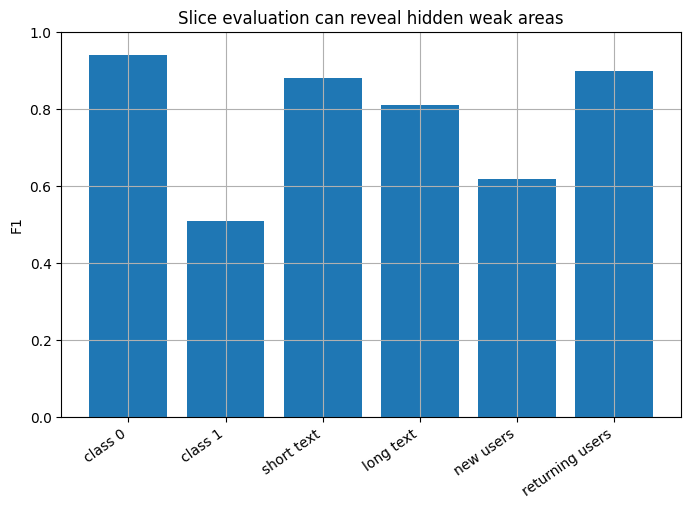

In [10]:
errors = pd.DataFrame({
    'slice':['class 0','class 1','short text','long text','new users','returning users'],
    'examples':[1200,120,500,820,300,1020],
    'F1':[0.94,0.51,0.88,0.81,0.62,0.90]
})
display(errors)
plt.bar(errors['slice'], errors['F1'])
plt.xticks(rotation=35, ha='right')
plt.ylim(0,1)
plt.title('Slice evaluation can reveal hidden weak areas')
plt.ylabel('F1');


## Step 15: Practical Dataset Audit Lab

**Definition:** A dataset audit is a systematic check of whether the dataset is valid for training and evaluation.

Check:

* duplicate rows or duplicate entities;
* missing labels;
* impossible feature values;
* target leakage columns;
* class imbalance;
* train/test distribution mismatch;
* group/time leakage.


In [11]:
audit = pd.DataFrame({
    'user_id':[1,2,2,3,4,5,6,7],
    'age':[25,32,32,-5,44,51,200,29],
    'days_since_signup':[10,20,20,5,100,300,2,7],
    'future_refund_issued':[0,1,1,0,0,1,0,0],
    'target_churn':[0,1,1,0,0,1,0,0]
})
checks = {
    'duplicate_user_rows': audit.duplicated('user_id').sum(),
    'invalid_age_count': ((audit.age < 0) | (audit.age > 120)).sum(),
    'missing_target_count': audit.target_churn.isna().sum(),
    'possible_leakage_columns': [c for c in audit.columns if 'future' in c.lower()]
}
display(audit)
display(pd.DataFrame({'check':checks.keys(), 'result':list(checks.values())}))


,user_id,age,days_since_signup,future_refund_issued,target_churn
0,1,25,10,0,0
1,2,32,20,1,1
2,2,32,20,1,1
3,3,-5,5,0,0
4,4,44,100,0,0
5,5,51,300,1,1
6,6,200,2,0,0
7,7,29,7,0,0


,check,result
0,duplicate_user_rows,1
1,invalid_age_count,2
2,missing_target_count,0
3,possible_leakage_columns,[future_refund_issued]


**Output meaning:** the audit catches duplicate entity rows, impossible ages, and a future-derived column. These issues should be fixed before model training.


## Step 16: Leakage Simulation Lab

Leakage can make validation look perfect. The model appears smart because the dataset accidentally gives away the answer.


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

X_base, y_base = make_classification(n_samples=2000, n_features=8, n_informative=3, random_state=7)
leak_feature = y_base + rng.normal(scale=0.02, size=len(y_base))
X_leaky = np.c_[X_base, leak_feature]
for name, Xmat in [('without leakage', X_base), ('with leakage feature', X_leaky)]:
    Xtr, Xte, ytr, yte = train_test_split(Xmat, y_base, test_size=.3, random_state=7, stratify=y_base)
    clf = LogisticRegression(max_iter=1000).fit(Xtr,ytr)
    auc = roc_auc_score(yte, clf.predict_proba(Xte)[:,1])
    print(name, 'ROC-AUC:', round(auc,4))


without leakage ROC-AUC: 0.9148
with leakage feature ROC-AUC: 1.0


**Output meaning:** the leaky feature makes performance unrealistically high. In real projects, leakage is often less obvious than this but causes the same problem.


## Step 17: DataLoader and Collation Concept

**Definition:** A DataLoader is the component that turns a dataset into shuffled, batched tensors. Collation is the process of combining individual samples into one batch.

For fixed-size tabular data, collation is simple stacking. For variable-length text, collation must pad sequences and create masks.


In [13]:
sequences = [[5,7,2], [4,1], [9,8,3,2,1]]
max_len = max(len(s) for s in sequences)
padded = np.array([s + [0]*(max_len-len(s)) for s in sequences])
mask = (padded != 0).astype(int)
print('padded batch:\n', padded)
print('attention/padding mask:\n', mask)


padded batch:
 [[5 7 2 0 0]
 [4 1 0 0 0]
 [9 8 3 2 1]]
attention/padding mask:
 [[1 1 1 0 0]
 [1 1 0 0 0]
 [1 1 1 1 1]]


**Why this matters:** if padding is not masked, the model may learn from fake tokens.


## Step 18: Training Loop Failure Modes

| Failure | Symptom | Fix |
|---|---|---|
| forgot `zero_grad` | gradients grow unexpectedly | clear gradients before backward |
| forgot `model.train()` | dropout/BatchNorm behavior wrong | set train mode during training |
| forgot `model.eval()` | validation noisy or wrong | set eval mode during validation |
| optimizer not stepping | loss does not change | verify optimizer step and trainable params |
| detached graph | gradients are None | check tensor conversion/detach operations |
| wrong target shape | loss error or wrong learning | inspect output and target shapes |


## Step 19: Baseline Ladder

A strong project uses a ladder of baselines:

1. majority/random baseline;
2. simple rule baseline;
3. linear/logistic model;
4. small MLP;
5. full deep model;
6. tuned deep model.

If a deep model does not beat simpler baselines, the problem may be data, features, split, metric, or training setup.


In [14]:
baseline_ladder = pd.DataFrame({
    'level':[1,2,3,4,5],
    'baseline':['majority class','simple rule','logistic regression','small MLP','larger tuned model'],
    'purpose':['minimum sanity','domain intuition','linear separability','nonlinear baseline','final candidate']
})
display(baseline_ladder)


,level,baseline,purpose
0,1,majority class,minimum sanity
1,2,simple rule,domain intuition
2,3,logistic regression,linear separability
3,4,small MLP,nonlinear baseline
4,5,larger tuned model,final candidate


## Step 20: Experiment Tracking Table

Every meaningful run should be traceable. If you cannot tell which data, code, and config produced a metric, the experiment is not reliable.


In [15]:
runs = pd.DataFrame({
    'run_id':['run_001','run_002','run_003'],
    'data_version':['v1','v1','v2'],
    'model':['small_mlp','small_mlp','small_mlp'],
    'lr':[1e-3,3e-4,3e-4],
    'batch_size':[64,64,128],
    'val_f1':[0.71,0.74,0.78],
    'notes':['baseline','lower lr','new labels + larger batch']
})
display(runs)


,run_id,data_version,model,lr,batch_size,val_f1,notes
0,run_001,v1,small_mlp,0.0010,64,0.71,baseline
1,run_002,v1,small_mlp,0.0003,64,0.74,lower lr
2,run_003,v2,small_mlp,0.0003,128,0.78,new labels + larger batch


## Step 21: Hyperparameter Search Budget

Deep learning search should respect compute budget.

| Budget | Strategy |
|---|---|
| tiny | tune learning rate and batch size only |
| small | random search over LR, weight decay, dropout |
| medium | random/Bayesian search with early stopping |
| large | ASHA/Hyperband, multiple seeds, ablations |

**Common mistake:** tuning 20 hyperparameters with only enough compute for 5 runs.


## Step 22: Final Training Methodology Checklist

Before trusting a model, verify:

* task and metric are defined;
* split matches deployment;
* preprocessing is fit only on train;
* baseline is recorded;
* small-batch overfit test passed;
* train/validation curves are inspected;
* best checkpoint is saved;
* threshold is tuned on validation only;
* test set is used once;
* errors and slices are reviewed;
* run is reproducible.


## Module 07 Summary

Training methodology is the system around the model. A correct workflow defines the task, protects validation/test data, prevents leakage, fits preprocessing only on train data, uses meaningful metrics, compares baselines, reads learning curves, saves checkpoints, tracks experiments, and performs error analysis. Without this workflow, a deep model can look good in a notebook and fail in real use.
